# ConnectaTel | Análisis de comportamiento y segmentación de clientes

Proyecto de análisis exploratorio de datos de telecomunicaciones en Latinoamérica, con registros de actividad correspondientes a 2024. Se examina la calidad de los datos, se construyen indicadores de uso por cliente y se proponen segmentos para orientar decisiones comerciales.

**Herramientas:** Python, pandas, seaborn y matplotlib.

**Datos de entrada:** `plans.csv`, `users_latam.csv` y `usage.csv`. Los conjuntos originales no se incluyen en este repositorio; para reproducir el análisis deben colocarse en la carpeta `data/`.


--- 
## Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


> **Reproducibilidad:** este notebook utiliza archivos CSV no incluidos en el repositorio. Las salidas existentes reflejan la ejecución original; para recalcularlas se necesitan los datos fuente. Los umbrales de segmentación son reglas exploratorias, no un modelo validado de predicción.


In [1]:
# importar librerías

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# Colocar los tres archivos CSV originales en la carpeta data/ antes de ejecutar.
from pathlib import Path
DATA_DIR = Path('data')
plans = pd.read_csv(DATA_DIR / 'plans.csv')
users = pd.read_csv(DATA_DIR / 'users_latam.csv')
usage = pd.read_csv(DATA_DIR / 'usage.csv')


In [3]:
# mostrar las primeras 5 filas de plans

display(plans.head())



,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
display(users.head())


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
display(usage.head())

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)



plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
print("Información de plans:")
plans.info()

Información de plans:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
print("\nInformación de users:")
users.info()


Información de users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
print("\nInformación de usage:")
usage.info()


Información de usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---
## Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para usage
print("\nValores nulos en usage:")
print(usage.isna().sum())
# Calcular la proporción de valores nulos en usage
print("\nProporción de valores nulos en usage:")
print((usage.isna().mean() * 100).round(2))


Valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id           0.00
user_id      0.00
type         0.00
date         0.12
duration    55.19
length      44.74
dtype: float64


In [11]:
# cantidad de nulos para usage
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())
print("\nPorcentaje de valores nulos en usage:")
print((usage.isna().mean() * 100).round(2))


Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64

Porcentaje de valores nulos en usage:
id           0.00
user_id      0.00
type         0.00
date         0.12
duration    55.19
length      44.74
dtype: float64


## Diagnóstico

En `users`, la columna `city` tiene 11.72% de valores nulos. Se recomienda investigar estos casos antes de imputarlos o eliminarlos, porque podrían estar relacionados con un problema de desplazamiento en los datos.

La columna `churn_date` tiene 88.35% de valores nulos. Aunque normalmente una columna con más de 80% de nulos podría eliminarse, en este caso los valores faltantes probablemente indican que el cliente continúa activo, por lo que se recomienda conservarla.

En `usage`, la columna `date` tiene 0.12% de valores nulos. Como son pocos registros y no pueden ubicarse en el tiempo, se recomienda revisar esas filas y eliminarlas si no es posible recuperar la fecha.

Las columnas `duration` y `length` tienen 55.19% y 44.74% de valores nulos, respectivamente. Estos nulos parecen esperados según el tipo de actividad: las llamadas tienen duración y los mensajes tienen longitud, por lo que no se recomienda imputarlos ni eliminar las columnas.



### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
display(users.describe())


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` presenta valores entre 10000 y 13999, sin valores negativos ni resultados que parezcan inválidos. Funciona como identificador, por lo que no debe interpretarse mediante la media o la mediana.

- La columna `age` presenta un valor mínimo de -999, el cual es imposible como edad y probablemente funciona como sentinel para representar información faltante. Se recomienda reemplazar -999 por un valor nulo y después decidir cómo tratar esos registros. Las edades restantes llegan hasta 79 años y parecen estar dentro de un rango posible.

In [13]:
# explorar columnas numéricas de usage
display(usage.describe())

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` presentan valores positivos y dentro de los rangos esperados. Ambas funcionan como identificadores, por lo que sus promedios no tienen una interpretación relevante para el análisis.

- La columna `duration` presenta valores entre 0 y 120 minutos. Los valores de 0 deben revisarse porque podrían representar llamadas sin duración, mientras que los valores cercanos a 120 pueden ser atípicos, pero no necesariamente inválidos.

La columna `length` presenta valores entre 0 y 1490 caracteres. Los mensajes con longitud 0 deben investigarse, mientras que los valores muy altos pueden representar mensajes excepcionalmente largos y deberán analizarse posteriormente mediante métodos de detección de outliers.


In [14]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(f"\nValores de la columna {columna}:")
    print(users[columna].value_counts(dropna=False))




Valores de la columna city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores de la columna plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city`contiene seis ciudades válidas, además de 96 registros con el valor ?, que funciona como sentinel de información desconocida. También presenta 469 valores nulos que deben investigarse considerando el posible desplazamiento detectado previamente en los datos. Se recomienda reemplazar ? por un valor nulo para estandarizar los faltantes, pero no imputar ni eliminar todavía.

La columna `plan` contiene únicamente las categorías Basico y Premium, las cuales coinciden con los planes disponibles en el dataset plans. No se detectan valores inválidos.


In [15]:
# explorar columna categórica de usage

usage['type'].value_counts(dropna=False)



text    22092
call    17908
Name: type, dtype: int64

- La columna `type` contiene únicamente los valores text y call, que corresponden a los dos tipos de actividad esperados. No se observan categorías inválidas ni sentinels.


**Diagnóstico de valores inválidos o sentinels**

Se identificó el valor `-999` en la columna `age`, el cual es una edad imposible y debe reemplazarse por un valor nulo.

En la columna `city` se encontró el valor `?`, que representa información desconocida. Se recomienda reemplazarlo por un valor nulo para unificar la representación de los datos faltantes. Los nulos ya existentes deben investigarse antes de tomar una decisión, debido al posible desplazamiento de valores detectado previamente.

En `duration` y `length` aparecen valores mínimos de 0 y máximos considerablemente altos. Estos valores deben revisarse como posibles casos atípicos, pero no deben eliminarse todavía porque podrían representar comportamientos reales.

No se encontraron valores categóricos inválidos en las columnas `plan` y `type`, ni valores evidentemente incorrectos en los identificadores.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:

# Convertir a fecha la columna `date` de usage

usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date` aparecen registros de los años 2022, 2023, 2024 y 2026. Los 40 registros de 2026 están fuera del periodo del análisis, ya que la información del proyecto está registrada solamente hasta 2024. Por ello, estas fechas deben considerarse inválidas y reemplazarse por valores nulos o corregirse si existe una fuente confiable para recuperar la fecha real.

In [19]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, todos los registros válidos pertenecen al año 2024. También aparecen 50 valores nulos, que corresponden a fechas faltantes o inválidas convertidas en NaT durante la estandarización. Como representan solo el 0.12% de los registros y no permiten ubicar la actividad en el tiempo, se recomienda eliminarlos si no es posible recuperar la fecha original.  
Basaremos el análisis en estas fechas.

**Diagnóstico de fechas fuera de rango**

En la columna `reg_date` se encontraron 40 registros del año 2026. Estas fechas son inválidas para el análisis porque el dataset solo contiene información registrada hasta 2024. Se recomienda convertirlas en valores nulos y posteriormente decidir si pueden recuperarse o si deben excluirse del análisis.

En la columna `date` de `usage` no se encontraron años fuera de rango: todos los valores válidos corresponden a 2024. Sin embargo, existen 50 fechas nulas, por lo que se recomienda eliminar esos registros si no es posible recuperar la fecha, ya que no pueden utilizarse en análisis temporales.


---
## Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Evaluación de valores faltantes
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [24]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))


type
call    0.99933
text    0.00000
Name: length, dtype: float64


Los valores nulos de duration y length dependen de la columna type. Esto es esperado, ya que los mensajes no tienen duración y las llamadas no tienen longitud de texto. Por ello, se recomienda conservar estos valores como nulos y no imputarlos.

Sin embargo, los porcentajes no son exactamente del 100%, lo que indica que existen algunos registros inconsistentes que deberán revisarse.Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

---
## Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)


# Agrupar información por usuario
usage_agg = (
    usage
    .groupby("user_id")
    .agg({
        "is_text": "sum",
        "is_call": "sum",
        "duration": "sum"
    })
    .reset_index()
)

# Observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# Observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on="user_id",
    how="left"
)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024


**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:

# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

display(user_profile[columnas_numericas].describe())


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:

# Distribución porcentual del tipo de plan
distribucion_plan = (
    user_profile['plan']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(distribucion_plan)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---
## Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

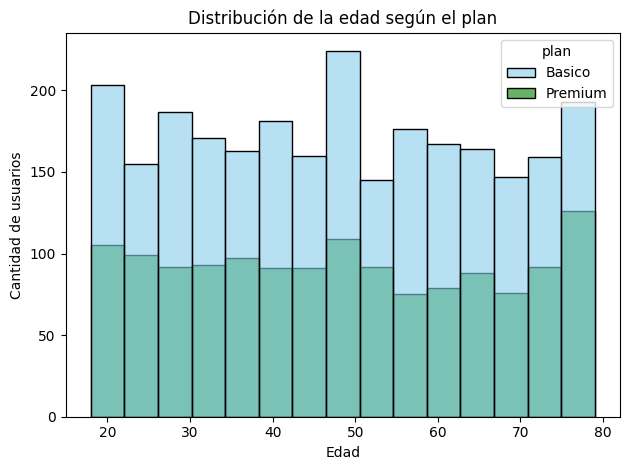

In [30]:

# Histograma para visualizar la edad
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)

plt.title('Distribución de la edad según el plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

💡Insights: 

La edad presenta una distribución bastante uniforme entre aproximadamente 18 y 79 años, sin un sesgo claro hacia la derecha o hacia la izquierda. Los usuarios de los planes Básico y Premium se encuentran distribuidos en casi todos los rangos de edad, por lo que no se observa una diferencia marcada entre el tipo de plan y la edad.

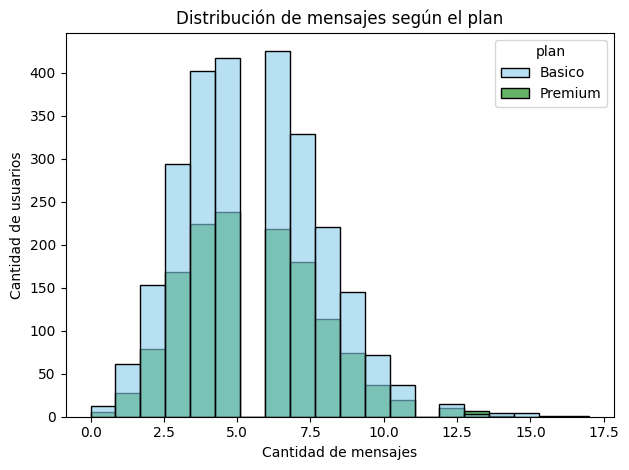

In [31]:
# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    alpha=0.6
)

plt.title('Distribución de mensajes según el plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

💡Insights: 

La mayoría de los usuarios envía entre 3 y 8 mensajes durante el periodo analizado. La distribución presenta un ligero sesgo hacia la derecha, debido a que existen pocos usuarios que envían más de 10 mensajes y algunos alcanzan valores cercanos a 17.

Los dos planes muestran un comportamiento similar y se superponen en casi todos los rangos, por lo que no se observa una diferencia clara en la cantidad de mensajes según el plan.

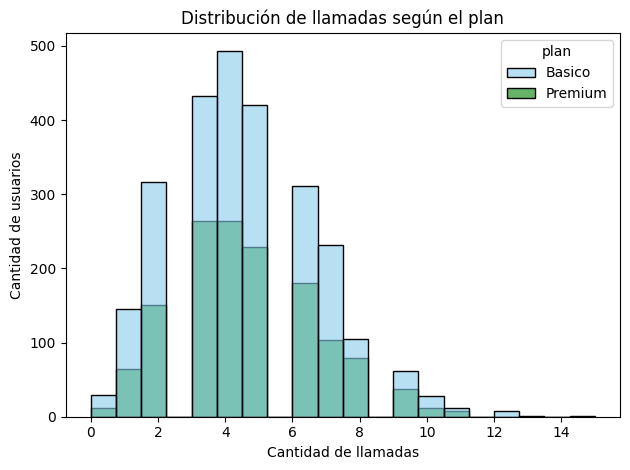

In [32]:
# Histograma para visualizar la cant_llamadas

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    alpha=0.6
)

plt.title('Distribución de llamadas según el plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

💡Insights: 

La mayoría de los usuarios acumula entre 5 y 40 minutos de llamada. La distribución está claramente sesgada hacia la derecha, porque la mayor concentración se encuentra en valores bajos y existe una cola larga hacia valores altos.

También se observan pocos usuarios con más de 80 minutos y algunos casos extremos cercanos a 140–155 minutos. Estos valores podrían considerarse atípicos y deberán revisarse posteriormente con un boxplot o mediante el método del IQR.

Los planes Básico y Premium muestran distribuciones similares, sin una diferencia clara en los minutos utilizados.

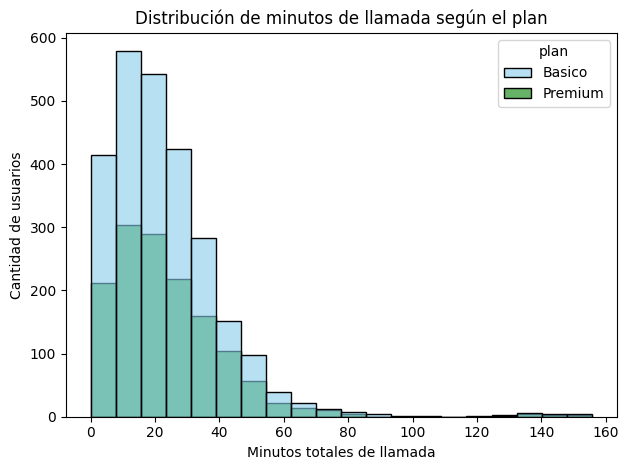

In [33]:
# Histograma para visualizar la cant_minutos_llamada

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=20,
    alpha=0.6
)

plt.title('Distribución de minutos de llamada según el plan')
plt.xlabel('Minutos totales de llamada')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

💡Insights: 

La mayoría de los usuarios acumula entre 5 y 40 minutos de llamada. La distribución está claramente sesgada hacia la derecha, porque la mayor concentración se encuentra en valores bajos y existe una cola larga hacia valores altos.

También se observan pocos usuarios con más de 80 minutos y algunos casos extremos cercanos a 140–155 minutos. Estos valores podrían considerarse atípicos y deberán revisarse posteriormente con un boxplot o mediante el método del IQR.

Los planes Básico y Premium muestran distribuciones similares, sin una diferencia clara en los minutos utilizados.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

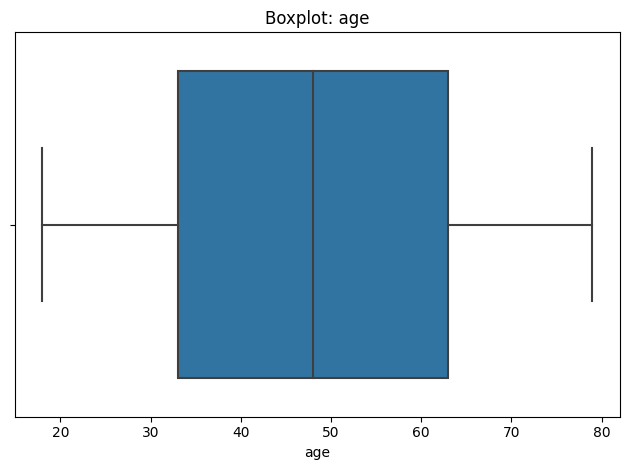

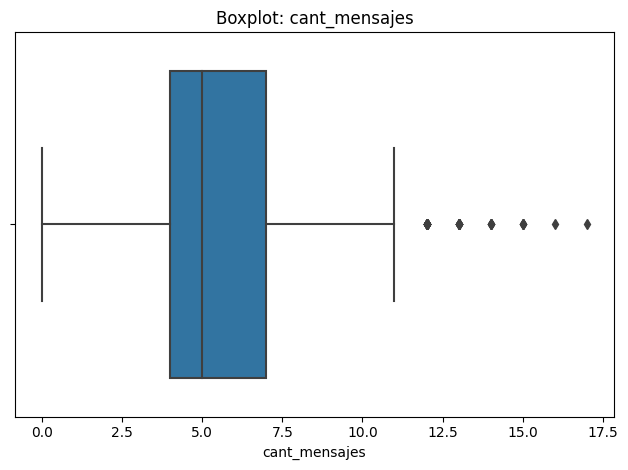

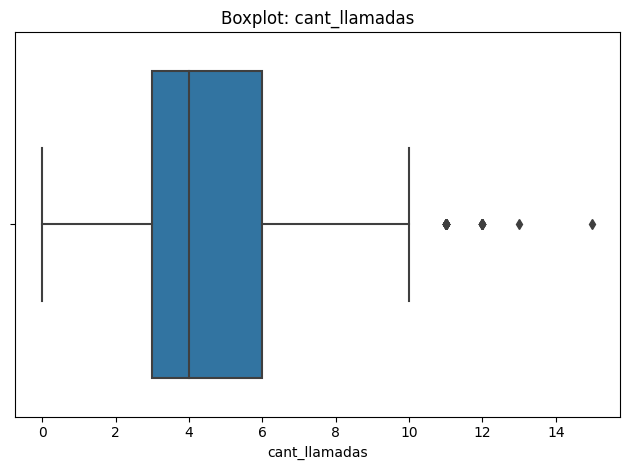

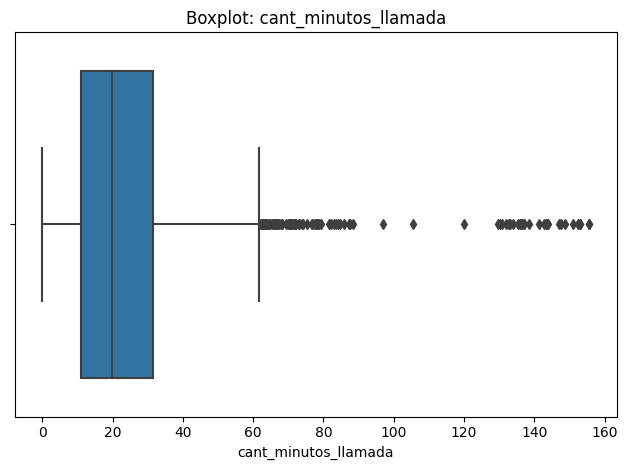

In [34]:

# Visualizando usando BoxPlot
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_numericas:
    sns.boxplot(
        data=user_profile,
        x=col
    )

    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

💡Insights: 

- Age: La edad no presenta valores atípicos. La mediana se encuentra cerca de los 48 años y la mayor parte de los usuarios está aproximadamente entre 33 y 63 años. Los valores mínimos y máximos, cercanos a 18 y 79 años, se encuentran dentro de un rango posible.
- cant_mensajes: La mediana es de aproximadamente 5 mensajes y la mayoría de los usuarios envía entre 4 y 7 mensajes. Se observan valores atípicos a partir de aproximadamente 12 mensajes, con algunos usuarios que alcanzan hasta 17. Estos valores no necesariamente son errores; pueden representar usuarios con un uso de mensajería mayor al habitual.

- cant_llamadas: La mediana es de aproximadamente 4 llamadas y la mayor parte de los usuarios realiza entre 3 y 6 llamadas. Se identifican valores atípicos por encima de 10 llamadas, con casos que llegan aproximadamente hasta 15. Estos usuarios presentan una frecuencia de llamadas superior al comportamiento típico y podrían analizarse como un segmento de alto uso.

- cant_minutos_llamada: La mediana se encuentra cerca de 20 minutos y la mayoría de los usuarios acumula aproximadamente entre 10 y 30 minutos de llamada. Se observa una gran cantidad de valores atípicos por encima de aproximadamente 60 minutos, incluyendo algunos casos cercanos a 130–155 minutos. Esta variable presenta una fuerte dispersión hacia valores altos. Los casos atípicos podrían representar usuarios intensivos, comportamientos inusuales o posibles errores de registro, por lo que deben revisarse antes de tomar una decisión.

In [35]:

# Calcular límites superiores con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1

    limite_superior = q3 + 1.5 * iqr

    print(f'\nColumna: {col}')
    print(f'Q1: {q1}')
    print(f'Q3: {q3}')
    print(f'IQR: {iqr}')
    print(f'Límite superior: {limite_superior}')
    print(f'Valor máximo: {user_profile[col].max()}')
    print(
        'Cantidad de outliers superiores:',
        (user_profile[col] > limite_superior).sum()
    )



Columna: cant_mensajes
Q1: 4.0
Q3: 7.0
IQR: 3.0
Límite superior: 11.5
Valor máximo: 17.0
Cantidad de outliers superiores: 46

Columna: cant_llamadas
Q1: 3.0
Q3: 6.0
IQR: 3.0
Límite superior: 10.5
Valor máximo: 15.0
Cantidad de outliers superiores: 30

Columna: cant_minutos_llamada
Q1: 11.12
Q3: 31.415
IQR: 20.295
Límite superior: 61.8575
Valor máximo: 155.69
Cantidad de outliers superiores: 109


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

-cant_mensajes: Se recomienda mantener los 46 outliers superiores. Aunque superan el límite de 11.5 mensajes, el valor máximo es 17, por lo que no parece un dato imposible. Estos registros probablemente representan usuarios con un uso de mensajería mayor al habitual y pueden ser útiles para identificar segmentos de alto consumo.

-cant_llamadas: Se recomienda mantener los 30 outliers superiores. Los valores mayores a 10.5 llamadas y hasta un máximo de 15 siguen siendo posibles dentro del comportamiento real de los usuarios. Eliminarlos podría hacer que se pierda información relevante sobre clientes que utilizan con mayor frecuencia el servicio de llamadas.

-cant_minutos_llamada: Se recomienda mantener los 109 outliers superiores, pero analizarlos con mayor atención. Los valores por encima de 61.86 minutos son considerablemente mayores al comportamiento típico y alcanzan hasta 155.69 minutos. Sin embargo, no son necesariamente errores, ya que pueden corresponder a usuarios intensivos. Antes de eliminarlos, conviene revisar si sus registros son consistentes y utilizarlos para crear un segmento de alto consumo.



---
## Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso


**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [38]:

# Crear función para clasificar el uso
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

# Crear columna grupo_uso
user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)





In [39]:

# verificar cambios

user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de clientes por edad


**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:

# Crear función para clasificar por edad
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

# Crear columna grupo_edad
user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)



In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de los segmentos


**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

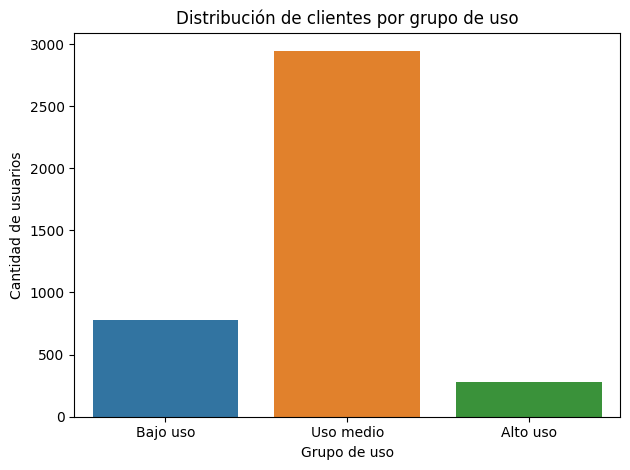

In [43]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()

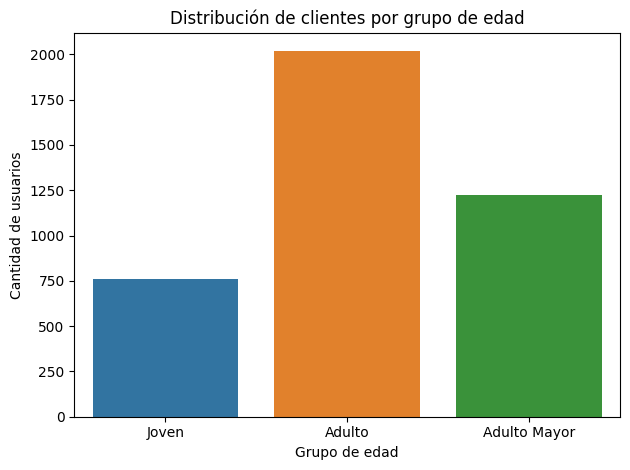

In [44]:
# Visualización de los segmentos por edad

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.tight_layout()
plt.show()


In [45]:
print(user_profile['grupo_uso'].value_counts())
print(user_profile['grupo_edad'].value_counts())
print()
print(
    (user_profile['grupo_uso'].value_counts(normalize=True) * 100).round(2)
)

print(
    (user_profile['grupo_edad'].value_counts(normalize=True) * 100).round(2)
)

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

Uso medio    73.58
Bajo uso     19.45
Alto uso      6.98
Name: grupo_uso, dtype: float64
Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64



---
## Paso 7: Insight Ejecutivo para Stakeholders


**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?



### Análisis ejecutivo

#### ⚠️ Problemas detectados en los datos

Antes de analizar el comportamiento de los clientes, se identificaron problemas de calidad que podían afectar los resultados:

- La columna `age` contenía el valor inválido `-999`, utilizado como sentinel para representar edades faltantes. Este valor se reemplazó por la mediana de las edades válidas.
- En `city` se encontraron **469 valores nulos (11.72%)** y **96 registros con `?` (2.40%)**. El símbolo `?` se convirtió en valor nulo para estandarizar la información faltante.
- En `churn_date` se identificaron **3534 valores nulos (88.35%)**. Estos registros se conservaron porque probablemente representan clientes que continúan activos y, por lo tanto, no tienen fecha de cancelación.
- En `reg_date` aparecieron **40 registros de 2026 (1% de los usuarios)**. Como los datos del proyecto solo abarcan hasta 2024, estas fechas se consideraron inválidas y se marcaron como nulas.
- En `usage`, la columna `date` presentó **50 valores nulos (0.12%)**, que no permiten ubicar esas actividades en el tiempo.
- `duration` tenía **55.19% de valores nulos** y `length` **44.74%**. Estos nulos se conservaron porque dependen del tipo de actividad: los mensajes no tienen duración y las llamadas no tienen longitud de texto.

La limpieza permitió trabajar con datos más consistentes sin eliminar información que pudiera tener valor para el negocio.

#### 🔍 Segmentos por edad

Se identificaron tres grupos de clientes:

- **Adultos:** 2018 usuarios, equivalentes al **50.45%**.
- **Adultos Mayores:** 1222 usuarios, equivalentes al **30.55%**.
- **Jóvenes:** 760 usuarios, equivalentes al **19%**.

La mitad de la base de clientes está formada por adultos de 30 a 59 años. Los adultos mayores también representan una proporción importante, mientras que los jóvenes constituyen el grupo menos numeroso.

La distribución de edades es relativamente uniforme y no presenta valores atípicos importantes. Además, al comparar los planes Básico y Premium, no se observaron diferencias claras en la distribución de edad. Esto indica que la edad, por sí sola, no parece determinar el plan contratado.

#### 📊 Segmentos por nivel de uso

Los clientes se clasificaron de acuerdo con la cantidad de llamadas y mensajes registrados:

- **Uso medio:** 2943 usuarios, equivalentes al **73.58%**.
- **Bajo uso:** 778 usuarios, equivalentes al **19.45%**.
- **Alto uso:** 279 usuarios, equivalentes al **6.98%**.

El segmento predominante es el de uso medio, por lo que representa el comportamiento típico de los clientes de ConnectaTel. El grupo de alto uso es pequeño, pero presenta mayores necesidades de comunicación y puede tener potencial para contratar planes con más beneficios. Por otro lado, los clientes de bajo uso podrían estar pagando por servicios que utilizan poco.

En los histogramas, los planes Básico y Premium mostraron distribuciones similares en mensajes, llamadas y minutos de llamada. Las barras del plan Básico fueron generalmente más altas porque existen más clientes con ese plan, no porque cada usuario tenga necesariamente un consumo mayor.

Por ello, con los resultados actuales no se observa una diferencia marcada en el comportamiento individual de uso entre los dos planes. Esto puede indicar que la oferta actual no está diferenciando suficientemente las necesidades reales de los clientes.

➡️ Esto sugiere que ConnectaTel tiene una base concentrada principalmente en clientes adultos y de uso medio, pero también cuenta con dos grupos que requieren propuestas diferentes: clientes de bajo consumo sensibles al precio y clientes intensivos que podrían necesitar más capacidad.

#### 📈 Patrones de uso extremo

El método del rango intercuartílico permitió identificar usuarios con consumos superiores al comportamiento habitual:

- En `cant_mensajes` se encontraron **46 outliers superiores**. El límite fue de 11.5 mensajes y el máximo registrado fue de 17.
- En `cant_llamadas` se encontraron **30 outliers superiores**. El límite fue de 10.5 llamadas y el máximo fue de 15.
- En `cant_minutos_llamada` se identificaron **109 outliers superiores**. El límite fue de 61.86 minutos y el máximo alcanzó 155.69 minutos.

Los valores atípicos no se eliminaron porque siguen siendo posibles y pueden corresponder a usuarios reales de alto consumo. La variable con mayor cantidad y magnitud de outliers fue la de minutos de llamada, lo que indica que algunos clientes realizan llamadas considerablemente más largas que el comportamiento típico.

Estos usuarios pueden ser valiosos para el negocio porque podrían necesitar planes con más minutos incluidos. Sin embargo, los casos más extremos también deben revisarse para descartar errores de captura, uso compartido de líneas o comportamientos inusuales.

#### 💼 Segmentos más valiosos para ConnectaTel

El segmento de **uso medio** es estratégico por su tamaño, ya que representa casi tres cuartas partes de la base de clientes. Mejoras pequeñas en su satisfacción, retención o migración de plan podrían producir un impacto comercial considerable.

El segmento de **alto uso**, aunque representa solamente el 6.98%, también puede ser especialmente valioso porque sus clientes tienen mayores necesidades de llamadas y mensajes. Este grupo podría estar dispuesto a contratar planes con más beneficios o pagar por servicios adicionales.

El segmento de **bajo uso** debe atenderse principalmente desde una perspectiva de retención. Estos clientes podrían percibir poco valor si pagan por beneficios que no utilizan, por lo que una opción más económica podría reducir el riesgo de cancelación.

#### 💡 Recomendaciones

1. **Crear un plan de bajo consumo** con una mensualidad menor y beneficios básicos para los clientes que realizan pocas llamadas y envían pocos mensajes.

2. **Fortalecer el plan intermedio**, ya que el 73.58% de los clientes pertenece al grupo de uso medio. Este plan debería ofrecer un equilibrio claro entre precio, llamadas, mensajes y datos incluidos.

3. **Diseñar una alternativa de alto consumo** con más minutos y mensajes para los usuarios intensivos, especialmente aquellos que superan los límites detectados mediante IQR.

4. **Identificar clientes de alto uso que estén en el plan Básico** para ofrecerles una migración al plan Premium o a una nueva opción con mayor capacidad.

5. **Revisar clientes de bajo uso que tengan el plan Premium**, ya que podrían estar pagando por beneficios que no necesitan y presentar mayor riesgo de insatisfacción.

6. **Analizar individualmente los 109 casos atípicos en minutos de llamada**, principalmente los valores cercanos al máximo de 155.69 minutos, para distinguir entre consumo intensivo y posibles inconsistencias.

7. **Diseñar estrategias de comunicación para adultos y adultos mayores**, debido a que juntos representan el 81% de la base de clientes.

8. **Mejorar las reglas de validación de datos** para impedir edades imposibles, fechas futuras, ciudades registradas con símbolos y actividades incompatibles con su tipo.

En conclusión, la oferta comercial debería basarse más en el comportamiento real de consumo que únicamente en características demográficas. La creación de planes diferenciados para usuarios de bajo, medio y alto uso permitiría ofrecer beneficios más adecuados, mejorar la percepción de valor y aumentar las oportunidades de retención y migración.